# 05 召回价值测算与 A/B 实验设计

**业务问题**：召回一位高价值风险用户值多少？每人能承受的触达成本上限是多少？如何用实验验证召回效果？

**核心结论**

- 每多召回一位高价值风险用户，14 天增量 GMV 约 59（原始价格单位）。即使触达能把回流率提高 10 个百分点，每触达一人的增量 GMV 也只有 3–6。
  **适合 Push、站内信等低成本渠道；发券需要用实测效果核算。**
- 实验以 **7 天回流率为主指标**：检测 2 个百分点的提升，每组约需 9,300 人，约 1 天的流量即可满足。GMV 波动过大，作为次要指标和护栏指标。
- 在真实数据上做了 500 次 A/A 检验，假阳性率 4.8%，分析方法可以用于正式实验。

价值测算只使用大促前的数据（11-01 ~ 11-14），避开购买数据缺失和大促当天的异常 GMV。

In [1]:
from nbutils import *
import numpy as np
from scipy import stats
from statsmodels.stats.power import NormalIndPower, TTestIndPower
from statsmodels.stats.proportion import proportion_effectsize

## 1. 目标人群：10-31 这天的高价值风险用户

站在 10-31，取早期风险层和加速流失层里各自历史强度前 30% 的用户（报告 03 的定义），
看他们 7 天内（到 11-07）有没有自然回来，以及 14 天内（11-01 ~ 11-14）贡献了多少 GMV。

In [2]:
t = q("""
    WITH st AS (
        SELECT v.user_id,
               DATE '2019-10-31' - v.event_date      AS recency,
               DATE '2019-10-31' - v.first_seen_date AS tenure,
               v.cum_events, v.cum_gmv, v.next_active_date
        FROM dws_user_visit_interval v
        WHERE v.event_date <= DATE '2019-10-31'
          AND (v.next_active_date IS NULL OR v.next_active_date > DATE '2019-10-31')
    ),
    s AS (SELECT *, lifecycle_stage(tenure, recency) AS stage FROM st),
    r AS (
        SELECT *, PERCENT_RANK() OVER (PARTITION BY stage ORDER BY cum_events DESC) < 0.3 AS top30
        FROM s WHERE stage IN ('early_risk', 'accelerating')
    ),
    y AS (
        SELECT user_id, SUM(gmv) AS gmv14, SUM(orders) AS orders14
        FROM dws_user_daily WHERE event_date BETWEEN '2019-11-01' AND '2019-11-14'
        GROUP BY 1
    )
    SELECT r.user_id, r.stage, r.cum_events, r.cum_gmv,
           CASE WHEN r.next_active_date <= DATE '2019-11-07' THEN 1 ELSE 0 END AS return_7d,
           COALESCE(y.gmv14, 0) AS gmv14, COALESCE(y.orders14, 0) AS orders14
    FROM r LEFT JOIN y USING (user_id)
    WHERE r.top30
""")
g = t.groupby("return_7d").agg(users=("user_id", "size"), gmv14=("gmv14", "mean"), buy_rate=("orders14", lambda x: (x > 0).mean()))
g.index = ["7 天内没回来", "7 天内自然回来"]
print(f"目标人群 {len(t):,} 人（早期风险 {(t.stage == 'early_risk').sum():,}，加速流失 {(t.stage == 'accelerating').sum():,}），"
      f"7 天自然回流率 {t.return_7d.mean():.1%}")
g.rename(columns={"users": "人数", "gmv14": "人均 14 天 GMV", "buy_rate": "14 天内下单比例"}) \
 .style.format({"人数": "{:,}", "人均 14 天 GMV": "{:.1f}", "14 天内下单比例": "{:.1%}"})

目标人群 598,033 人（早期风险 228,382，加速流失 369,651），7 天自然回流率 24.5%


,人数,人均 14 天 GMV,14 天内下单比例
7 天内没回来,"451,534",6.1,1.4%
7 天内自然回来,"146,499",64.9,12.5%


## 2. 单用户召回价值与盈亏平衡

一位「本不会回流、被成功召回」的用户带来的增量 GMV，用两组之差估计：

$$\Delta V = \overline{\text{GMV}}_{\text{自然回来}} - \overline{\text{GMV}}_{\text{没回来}}$$

这一估计偏乐观：自然回流的用户购买意愿本来就更强，被召回的用户通常更犹豫。因此再乘以质量折扣 $m$（取 1 和 0.5 两档）。

每触达一个人能承受的最高成本（盈亏平衡点）：

$$\text{break-even} = \Delta p \times \Delta V \times m \times \text{毛利率}$$

其中 $\Delta p$ 是触达把 7 天回流率提高了多少——这正是实验要测的东西，这里先给几档假设。

In [3]:
dV = t.loc[t.return_7d == 1, "gmv14"].mean() - t.loc[t.return_7d == 0, "gmv14"].mean()
buyers_only = t.loc[(t.return_7d == 1) & (t.orders14 > 0), "gmv14"].mean()
rows = []
for dp in (0.02, 0.05, 0.10):
    for m in (1.0, 0.5):
        rows.append({"Δp（回流率提升）": dp, "质量折扣 m": m, "每人增量 GMV": dp * dV * m,
                     "毛利率 10%": dp * dV * m * 0.10, "毛利率 20%": dp * dV * m * 0.20})
be = pd.DataFrame(rows)
print(f"ΔV = {dV:.1f}（原始价格单位，14 天）")
print(f"注意：如果只在「回来且下了单」的人里求平均，会得到 {buyers_only:.0f}，比 ΔV 高 {buyers_only / dV:.0f} 倍——"
      f"回来的人里只有 {(t.loc[t.return_7d == 1, 'orders14'] > 0).mean():.0%} 会下单，没下单的人必须算进分母")
be.style.format({"Δp（回流率提升）": "{:.0%}", "质量折扣 m": "{:.1f}", "每人增量 GMV": "{:.2f}",
                 "毛利率 10%": "{:.3f}", "毛利率 20%": "{:.3f}"}).hide(axis="index")

ΔV = 58.9（原始价格单位，14 天）
注意：如果只在「回来且下了单」的人里求平均，会得到 518，比 ΔV 高 9 倍——回来的人里只有 13% 会下单，没下单的人必须算进分母


Δp（回流率提升）,质量折扣 m,每人增量 GMV,毛利率 10%,毛利率 20%
2%,1.0,1.18,0.118,0.236
2%,0.5,0.59,0.059,0.118
5%,1.0,2.94,0.294,0.589
5%,0.5,1.47,0.147,0.294
10%,1.0,5.89,0.589,1.178
10%,0.5,2.94,0.294,0.589


**结论：该人群值得召回，但应优先使用低成本渠道。**

- 即使触达能把回流率提高 10 个百分点，每触达一人带来的增量 GMV 也只有 3–6 个价格单位，折成毛利只有 0.3–1.2；
- Push、站内信、邮件这类边际成本接近 0 的渠道可以覆盖；**发优惠券要谨慎**——券面值会直接抵消增量，
  而且约四分之一（24.5%）本来就会自然回流的用户也会领券，这部分是纯成本；
- 这也是必须做实验的原因：Δp 是 2% 还是 10%，决定了能否使用优惠券。

毛利率是假设值（3C 电商的典型区间），数据里没有成本信息。

## 3. 实验设计

| 项 | 设计 |
|---|---|
| 假设 | 对沉默 6–8 天的高价值用户发一次「兴趣品类降价/新品」提醒，能提高 7 天回流率，且 14 天人均 GMV 不下降 |
| 实验对象 | 每天新进入「沉默第 7 天」且历史强度为当天前 30% 的用户；进入当天分组，之后不再变动 |
| 随机单位 | 用户。按 `hash(user_id + 实验名) mod 100` 分桶，50/50 |
| 分层 | 按「历史强度分位（前10% / 10–30%）× 是否下过单」分层随机，保证两组结构一致 |
| 实验组 | 触达一次（Push 或站内信），内容为该用户最常浏览品类的降价商品 |
| 对照组 | 不触达（**不是**「发一条无关消息」——要测的就是触达本身的增量） |
| 主指标 | 7 天回流率（进入实验后 7 天内至少来访一次） |
| 次指标 | 14 天人均 GMV（含 0）、14 天下单率 |
| 护栏指标 | 推送关闭率 / 退订率、投诉率（数据里没有，上线前需要埋点，见 `docs/tracking_plan.md`） |
| 时长 | 按下面的样本量算，不少于 14 天，覆盖完整的两个周循环 |
| 排除 | 7 天内被其他活动触达过的用户；大促前后 3 天不开新实验 |
| 决策规则 | 主指标显著为正、14 天人均 GMV 不显著为负、护栏不恶化 → 全量；不提前看结果停实验 |

为什么主指标用回流率而不是 GMV，见下面的样本量计算。

### 3.1 样本量与时长

主指标的基线：沉默 7 天的前 30% 用户，接下来 7 天自然回来的比例约 38%（报告 04）。

In [4]:
p0 = 0.38
daily = q("""
    SELECT event_date + 7 AS trigger_date, COUNT(*) FILTER (WHERE pr < 0.3) AS entrants
    FROM (SELECT *, PERCENT_RANK() OVER (PARTITION BY event_date ORDER BY cum_events DESC) AS pr
          FROM dws_user_visit_interval) v
    WHERE (next_active_date IS NULL OR next_active_date - event_date > 7)
      AND event_date + 7 BETWEEN '2019-10-15' AND '2019-11-14'
    GROUP BY 1
""").entrants.median()
power = NormalIndPower()
rows = []
for mde in (0.01, 0.02, 0.03):
    n = power.solve_power(effect_size=proportion_effectsize(p0 + mde, p0), alpha=0.05, power=0.8, ratio=1)
    rows.append({"最小可检测提升（绝对值）": mde, "每组样本量": n, "两组合计": 2 * n, "需要天数": 2 * n / daily})
print(f"每天新进入触发条件的人数（中位数）：{daily:,.0f}")
pd.DataFrame(rows).style.format({"最小可检测提升（绝对值）": "{:.0%}", "每组样本量": "{:,.0f}", "两组合计": "{:,.0f}",
                                 "需要天数": "{:.1f}"}).hide(axis="index")

每天新进入触发条件的人数（中位数）：18,232


最小可检测提升（绝对值）,每组样本量,两组合计,需要天数
1%,"37,167","74,334",4.1
2%,"9,335","18,669",1.0
3%,"4,167","8,333",0.5


回流率是二元指标、方差小：每天约 1.8 万人进入，**2 个百分点的提升 1 天就够样本**，1 个百分点也只要 4 天。
但仍然要跑满 14 天：回流有周内规律（报告 02），而且要等 14 天 GMV 的观察期。

再看如果拿 GMV 当主指标：

In [5]:
y = t.gmv14.to_numpy()
cap = np.quantile(y, 0.99)
yw = np.minimum(y, cap)
x = t.cum_gmv.to_numpy()
theta = np.cov(yw, x)[0, 1] / x.var()
y_cuped = yw - theta * (x - x.mean())
tt = TTestIndPower()
rows = []
for name, arr in [("原始 14 天 GMV", y), ("p99 截尾", yw), ("p99 截尾 + CUPED（用实验前 GMV 做协变量）", y_cuped)]:
    sd = arr.std()
    n = tt.solve_power(effect_size=0.10 * y.mean() / sd, alpha=0.05, power=0.8)
    rows.append({"处理方式": name, "标准差": sd, "检测 +10% 每组需要": n, "需要天数": 2 * n / daily})
pd.DataFrame(rows).style.format({"标准差": "{:.1f}", "检测 +10% 每组需要": "{:,.0f}", "需要天数": "{:.0f}"}).hide(axis="index")

处理方式,标准差,检测 +10% 每组需要,需要天数
原始 14 天 GMV,233.6,"204,182",22
p99 截尾,65.7,"16,162",2
p99 截尾 + CUPED（用实验前 GMV 做协变量）,65.1,"15,863",2


GMV 极度右偏（大部分人是 0，少数人买手机、电视），标准差是均值的 11 倍：不做处理，检测 10% 的提升每组要 20 万人、跑 22 天。
p99 截尾把标准差从 234 压到 66，样本量降到每组 1.6 万人；CUPED 在这里几乎没帮助——实验前 GMV 与实验期 GMV 的相关只有 0.16，
低频高客单的平台很难用上一次消费预测下一次。

**所以主指标用回流率**（直接对应召回动作，也最灵敏），**GMV 截尾后做次指标**，并以「GMV 不显著下降」作为护栏，
防止出现「用户回流了，但只领券不购买」的情况。

### 3.2 A/A 检验：在真实数据上验证分析方法

上线前先确认：把同一批用户随机分为两组、不做任何干预，检验方法是否会误报「显著」。
用 10-31 的目标人群随机分组 500 次，每次对回流率做双比例 z 检验、对截尾 GMV 做 Welch t 检验：

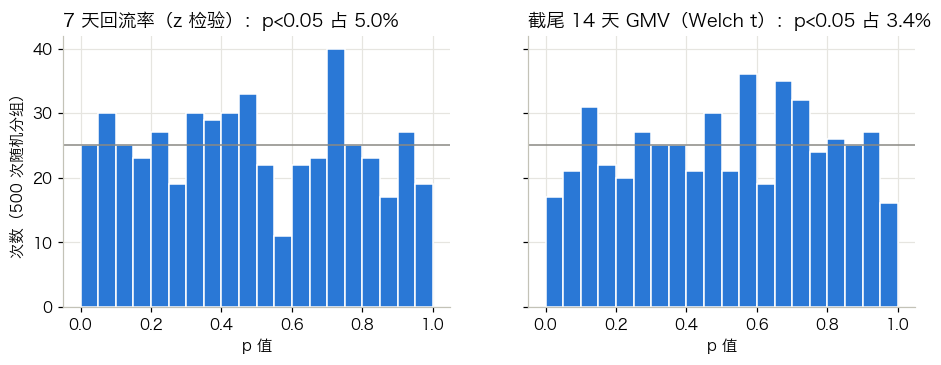

In [6]:
rng = np.random.default_rng(7)
ret = t.return_7d.to_numpy()
p_ret, p_gmv = [], []
for _ in range(500):
    g1 = rng.random(len(t)) < 0.5
    a, b = ret[g1], ret[~g1]
    pooled = ret.mean()
    z = (a.mean() - b.mean()) / np.sqrt(pooled * (1 - pooled) * (1 / len(a) + 1 / len(b)))
    p_ret.append(2 * stats.norm.sf(abs(z)))
    p_gmv.append(stats.ttest_ind(yw[g1], yw[~g1], equal_var=False).pvalue)
p_ret, p_gmv = np.array(p_ret), np.array(p_gmv)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, p, name in [(axes[0], p_ret, "7 天回流率（z 检验）"), (axes[1], p_gmv, "截尾 14 天 GMV（Welch t）")]:
    ax.hist(p, bins=20, range=(0, 1), color=PALETTE[0], edgecolor="white", linewidth=1)
    ax.axhline(len(p) / 20, color=GRAY, linewidth=1)
    ax.set(title=f"{name}：p<0.05 占 {np.mean(p < 0.05):.1%}", xlabel="p 值")
axes[0].set_ylabel("次数（500 次随机分组）")
plt.show()

两个指标在 A/A 下的 p 值都接近均匀分布，p<0.05 的比例在 5% 附近，说明检验方法的假阳性率符合预期，可以用于正式实验。

### 3.3 正式实验的分析清单

1. **SRM 检查**：两组人数比和 50/50 做卡方检验，p<0.001 说明分流有问题，结果作废；
2. **主指标**：双比例 z 检验 + 差值的 95% 置信区间；按分层做异质性分析（前10% vs 10–30%、下过单 vs 没下过）；
3. **次指标**：截尾 GMV 的 Welch t 检验，附 bootstrap 置信区间；
4. **ROI**：用实测的 Δp 代回第 2 节的公式，和真实触达成本比较；
5. **下一轮**：把触达时机做成实验维度（沉默第 4 天 / 第 7 天 / 第 12 天），直接验证报告 04 推断的触达窗口。

方案的文字版见 [docs/ab_test_plan.md](../docs/ab_test_plan.md)。